# Aprendizagem de Máquina I

## Hugo Tremonte de Carvalho

#### hugo@dme.ufrj.br

* NOME: João Victor Barboza Machado das Neves
* DRE: 117081393
* E-MAIL CADASTRADO NO CLASSROOM: j.victor.neves7@gmail.com

Este _notebook_ é correspondente ao nosso segundo projeto, passado no dia 14/11/2025 e para entrega no dia 05/12/2025. Ele consiste em resolver um problema prático. A entrega da atividade deve ser feita através do Google Classroom, fazendo um _upload_ deste _notebook_, devidamente atualizado com as suas resoluções e implementações. Recomendo fortemente que façam o trabalho no Google Colab, pois assim temos certa garantia de estarmos rodando tudo no mesmo ambiente e que eu conseguir executar o código de vocês sem dificuldades.

O projeto é **individual**.

O objetivo deste trabalho é analisar [esta](https://www.kaggle.com/fmena14/volcanoesvenus) base de dados, que contém imagens de satélite da superfície de Vênus, e deseja-se estudar a ocorrência ou não de vulcões na superfície do planeta. A base de dados está contida no arquivo `dataset.zip`, anexo junto com essa atividade no Google Classroom, e mais abaixo irei detalhar os seus 4 arquivos.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Eis aqui o conjunto de treinamento. Você pode (e deve!) fazer validação cruzada nele para comparar diversos classificadores, mas o conjunto de teste será mostrado mais abaixo. Note que não há necessidade de fazer `train_test_split` com a base carregada a seguir, pois mais adiante carregaremos o arquivo com o conjunto de teste!

In [ ]:
feat = pd.read_csv('train_images.csv', header = None) # 'header = None' é importante pois o .csv não tem cabeçalho.
                                                      # Sem 'header = None' a primeira imagem será lida como o nome das colunas do dataframe.
resp = pd.read_csv('train_labels.csv')

display(feat)

,0,1,2,3,4,5,6,7,8,9,...,12090,12091,12092,12093,12094,12095,12096,12097,12098,12099
0,95,101,99,103,95,86,96,89,70,104,...,111,107,92,89,103,99,117,116,118,96
1,91,92,91,89,92,93,96,101,107,104,...,103,92,93,95,98,105,104,100,90,81
2,87,70,72,74,84,78,93,104,106,106,...,84,71,95,102,94,80,91,80,84,90
3,0,0,0,0,0,0,0,0,0,0,...,94,81,89,84,80,90,92,80,88,96
4,114,118,124,119,95,118,105,116,123,112,...,116,113,102,93,109,104,106,117,111,115
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6995,90,96,88,95,94,100,95,80,80,71,...,88,83,72,76,73,79,76,79,84,69
6996,82,82,84,91,74,61,73,80,75,97,...,100,78,90,88,80,88,90,90,66,71
6997,133,102,121,133,129,131,98,121,123,125,...,120,123,119,111,104,102,119,130,131,111
6998,118,117,115,107,92,76,100,102,81,106,...,104,105,102,111,99,90,105,100,100,109


Cada linha do dataframe são os _pixels_ de uma imagem em tons de cinza de tamanho 110 x 110, "achatados" em um vetor de tamanho 12.100.

Note que cada _pixel_ corresponde a um valor inteiro entre 0 (totalmente preto) e 255 (totalmente branco). Talvez seja conveniente transformá-los em um número entre 0 e 1.

Vamos ver algumas das imagens na base de dados:

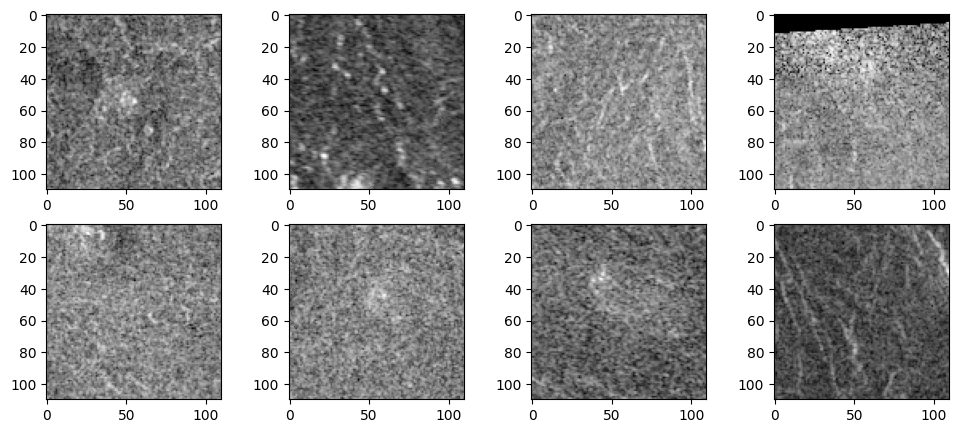

In [ ]:
fig, axs = plt.subplots(2, 4)
fig.set_size_inches(12, 5)
ind = 0

for ax in axs.flat:
    img = np.array(feat.iloc[ind]).reshape((110,110))
    ax.imshow(img, cmap = 'gray')
    ind += 1

Agora, vamos entender as variáveis resposta:

In [ ]:
resp.head()

,Volcano?,Type,Radius,Number Volcanoes
0,1,3.0,17.46,1.0
1,0,NaN,NaN,NaN
2,0,NaN,NaN,NaN
3,0,NaN,NaN,NaN
4,0,NaN,NaN,NaN


Eis o que cada informação na variável resposta significa:

 * Se ``Volcano? = 0``, então na respectiva imagem acredita-se fortemente que **não** há um vulcão
 * Se ``Volcano? = 1``, então acredita-se fortemente que naquela imagem há ao menos um vulcão, e nesse caso há informações adicionais:
   - ``Number Volcanoes`` representa quantos vulcões provavelmente há naquela imagem (nesse caso, há um vulcão centralizado na figura)
   - ``Radius`` é o raio do vulcão que está centralizado na imagem, medido em *pixels*
   - ``Type`` é uma variável que codifica a incerteza dos astrônomos sobre a existência de um vulcão naquela imagem:
     - ``Type = 1`` indica que a figura respectiva CERTAMENTE contém ao menos um vulcão
     - ``Type = 2`` indica que a figura respectiva PROVAVELMENTE contém ao menos um vulcão
     - ``Type = 3`` indica que a figura respectiva POSSIVELMENTE contém ao menos um vulcão
     - ``Type = 4`` indica que a figura respectiva mostra somente uma cratera

*Obs.: No caso de ``Volcano? = 0``, as outras variáveis são preenchidas com ``NaN``*

Note que a base de dados está desbalanceada.

Obs.: Gráfico de pizza só pra não perder a oportunidade de falar mal do gráfico de pizza e recomendar fortemente que vocês NÃO façam esse tipo de gráfico! :-)

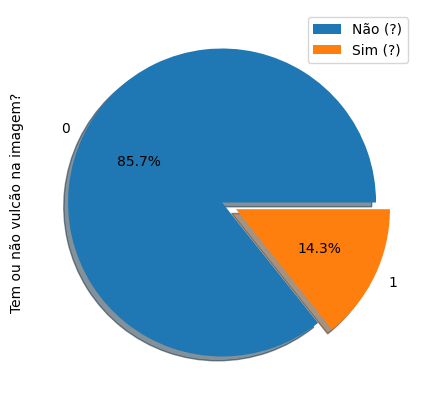

In [ ]:
resp['Volcano?'].value_counts().plot(
    kind = 'pie', explode = [0, 0.1], figsize = (5, 5), autopct = '%1.1f%%', shadow = True)
plt.ylabel('Tem ou não vulcão na imagem?')
plt.legend(['Não (?)', 'Sim (?)'])
plt.show()

Dentre as imagens que acredita-se ter um vulcão, vamos ver a distribuição dos quatro graus de incerteza possíveis:

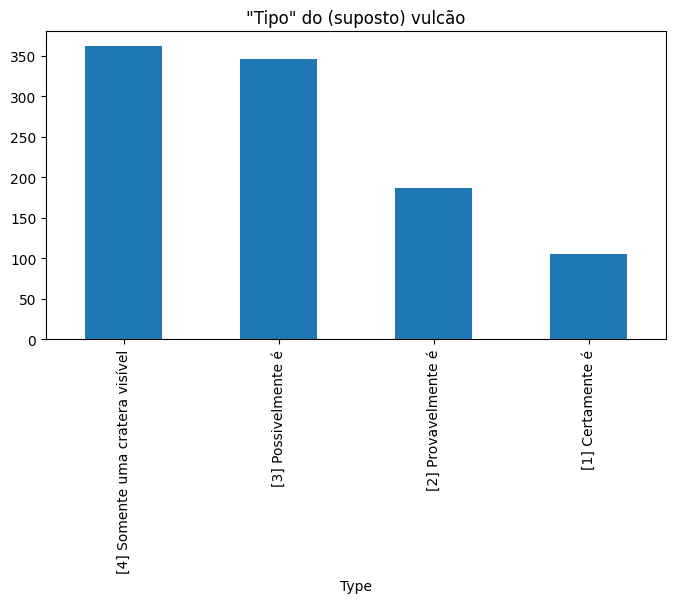

In [ ]:
resp[resp['Volcano?'] == 1]['Type'].value_counts().plot(kind = 'bar', legend = False, figsize = (8, 4))
plt.title('"Tipo" do (suposto) vulcão')
plt.xticks(np.arange(4), ['[4] Somente uma cratera visível', '[3] Possivelmente é', '[2] Provavelmente é', '[1] Certamente é'])
plt.show()

Temos uma variável resposta contínua, que é o raio do vulcão:

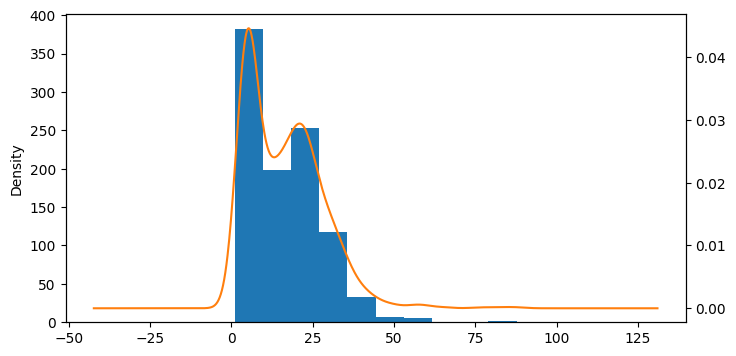

In [ ]:
ax = resp[resp['Volcano?'] == 1]['Radius'].plot(kind = 'hist', legend = False, figsize = (8, 4))
resp[resp['Volcano?'] == 1]['Radius'].plot(kind = 'kde', ax = ax, secondary_y = True)
plt.show()

Finalmente, estudando a quantidade suposta de vulcões na imagem:

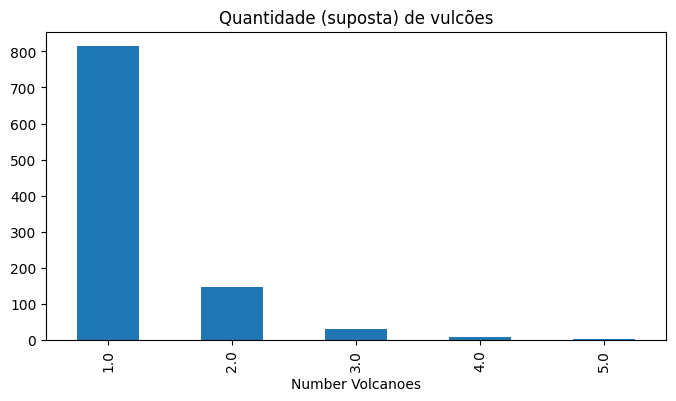

In [ ]:
plt.title('Quantidade (suposta) de vulcões')
resp[resp['Volcano?'] == 1]['Number Volcanoes'].value_counts().plot(kind = 'bar', legend = False, figsize = (8, 4))
plt.show()

Agora, vejamos alguns exemplos de imagens da base de dados com diversas das características vistas acima:

== IMAGEM SEM VULCÃO ==
Volcano?            0.0
Type                NaN
Radius              NaN
Number Volcanoes    NaN
Name: 1, dtype: float64


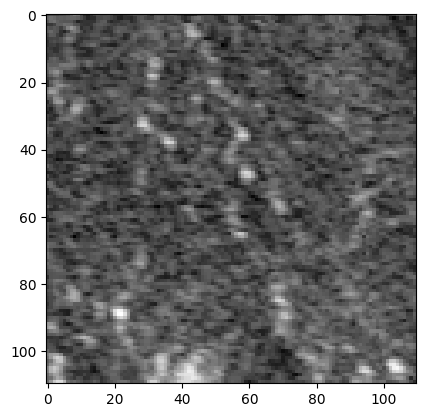

In [ ]:
print('== IMAGEM SEM VULCÃO ==')

print(resp.iloc[1])

image = np.array(feat.iloc[1]).reshape((110,110))
plt.figure()
plt.imshow(image,cmap="gray")
plt.show()

== IMAGEM COM VULCÃO ==
Volcano?             1.00
Type                 1.00
Radius              22.02
Number Volcanoes     1.00
Name: 9, dtype: float64


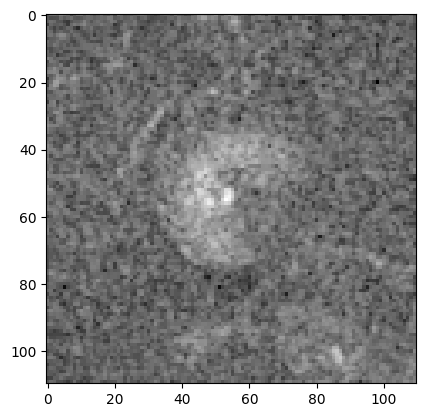

In [ ]:
print('== IMAGEM COM VULCÃO ==')

print(resp.iloc[9])

image = np.array(feat.iloc[9]).reshape((110,110))
plt.figure()
plt.imshow(image,cmap="gray")
plt.show()

== IMAGEM COM VULCÃO ==
Volcano?             1.00
Type                 2.00
Radius              19.31
Number Volcanoes     1.00
Name: 38, dtype: float64


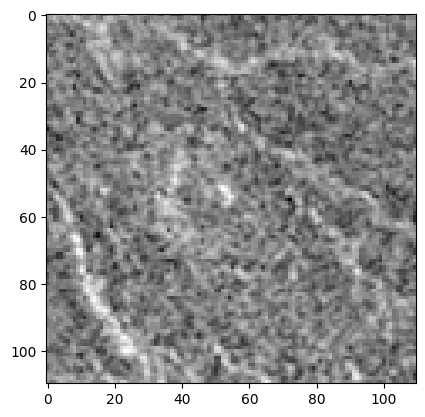

In [ ]:
print('== IMAGEM COM VULCÃO ==')

print(resp.iloc[38])

image = np.array(feat.iloc[38]).reshape((110,110))
plt.figure()
plt.imshow(image,cmap="gray")
plt.show()

== IMAGEM COM VULCÃO ==
Volcano?             1.00
Type                 3.00
Radius              17.46
Number Volcanoes     1.00
Name: 0, dtype: float64


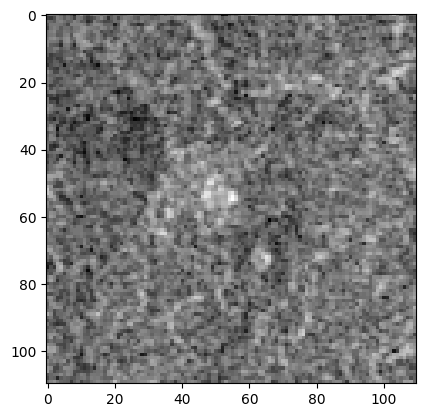

In [ ]:
print('== IMAGEM COM VULCÃO ==')

print(resp.iloc[0])

image = np.array(feat.iloc[0]).reshape((110,110))
plt.figure()
plt.imshow(image,cmap="gray")
plt.show()

== IMAGEM COM VULCÃO ==
Volcano?            1.0
Type                4.0
Radius              8.0
Number Volcanoes    2.0
Name: 55, dtype: float64


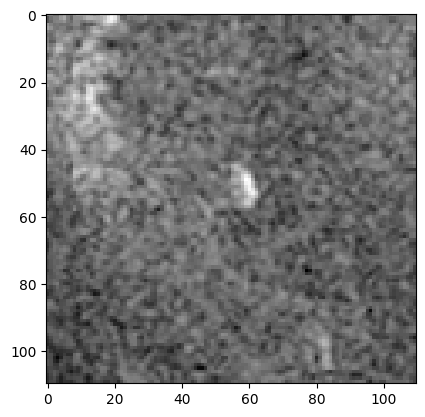

In [ ]:
print('== IMAGEM COM VULCÃO ==')

print(resp.iloc[55])

image = np.array(feat.iloc[55]).reshape((110,110))
plt.figure()
plt.imshow(image,cmap="gray")
plt.show()

== IMAGEM COM VULCÃO ==
Volcano?             1.00
Type                 3.00
Radius              21.63
Number Volcanoes     2.00
Name: 34, dtype: float64


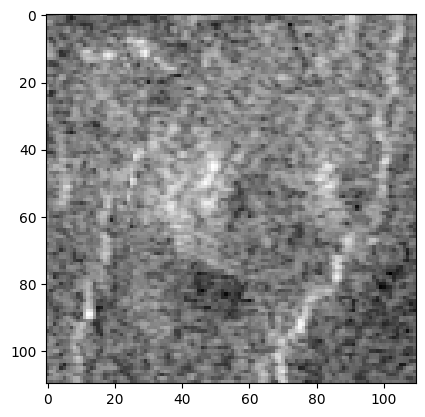

In [ ]:
print('== IMAGEM COM VULCÃO ==')

print(resp.iloc[34])

image = np.array(feat.iloc[34]).reshape((110,110))
plt.figure()
plt.imshow(image,cmap="gray")
plt.show()

== IMAGEM COM VULCÃO ==
Volcano?             1.00
Type                 2.00
Radius              24.33
Number Volcanoes     3.00
Name: 596, dtype: float64


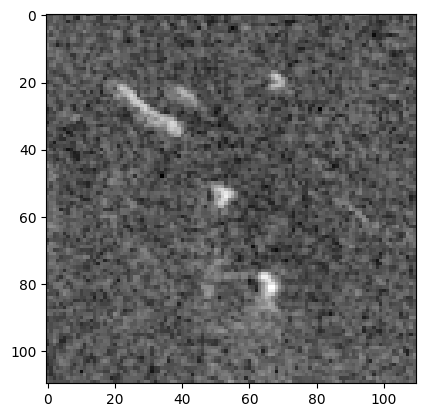

In [ ]:
print('== IMAGEM COM VULCÃO ==')

print(resp.iloc[596])

image = np.array(feat.iloc[596]).reshape((110,110))
plt.figure()
plt.imshow(image,cmap="gray")
plt.show()

== IMAGEM COM VULCÃO ==
Volcano?            1.00
Type                4.00
Radius              3.61
Number Volcanoes    4.00
Name: 425, dtype: float64


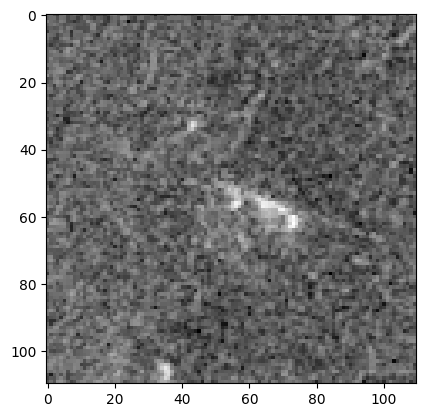

In [ ]:
print('== IMAGEM COM VULCÃO ==')

print(resp.iloc[425])

image = np.array(feat.iloc[425]).reshape((110,110))
plt.figure()
plt.imshow(image,cmap="gray")
plt.show()

== IMAGEM COM VULCÃO ==
Volcano?            1.00
Type                3.00
Radius              5.83
Number Volcanoes    5.00
Name: 853, dtype: float64


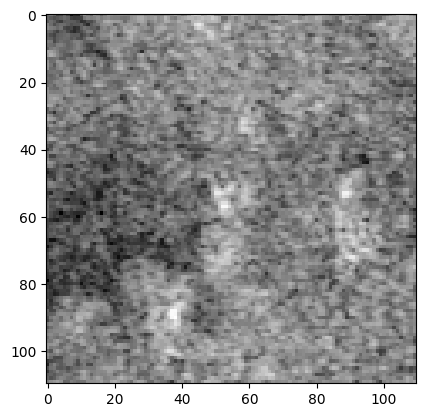

In [ ]:
print('== IMAGEM COM VULCÃO ==')

print(resp.iloc[853])

image = np.array(feat.iloc[853]).reshape((110,110))
plt.figure()
plt.imshow(image,cmap="gray")
plt.show()

## Objetivos

O principal objetivo do projeto é:

* Prever, **somente a partir da imagem**, se naquela foto há ou não um vulcão. Ou seja, deve ser resolvido o problema de **classificação binária** onde os dados observados são as linhas do DataFrame ``feat`` e a variável resposta é a coluna ``Volcano?`` do DataFrame ``resp``.

Para isso, você deverá testar todos os classificadores que aprendemos no curso, otimizar os hiperparâmetros (quando pertinente) e escolher qual é o melhor classificador, utilizando o conjunto de treinamento. Finalmente, compare o desempenho de todos eles no conjunto de teste, e decida por um classificador bom para esse problema.

Como de costume, o treinamento dos classificadores e a validação cruzada para otimização dos hiperparâmetros é um procedimento a ser realizado somente no conjunto de **treinamento**, já carregado. A performance dos melhores classificadores elencados deve ser aferida no conjunto de **teste**, carregado abaixo:

In [ ]:
feat_test = pd.read_csv('test_images.csv', header = None) # Utilizar 'header = None' pelo mesmo motivo acima.
resp_test = pd.read_csv('test_labels.csv')

### Informações importantes

* Justifique se você deve tomar mais cuidado com falsos negativos ou falsos positivos no objetivo do projeto.


* Você deve entregar:
  - Um Notebook do Jupyter contendo os seus códigos.
  - Células de *markdown* neste notebook, na forma de um relatório, explicando **claramente** o procedimento que te levou a tais classificadores, como se fosse um resumo de sua investigação. Entregar somente códigos sem explicação **não** é suficiente! Eu tenho que conseguir entender quais foram suas ideias e desenvolvimentos **somente a partir do texto**, sem ter que recorrer ao código. Isso é importante para vocês treinarem a escrita!

* Algumas observações:
  - Descreva o resultado que você obteve, e não somente mostre métricas sem justificativa.
  - A base de dados é **bastante** pesada: 7.000 observações de 12.100 atributos (olha o cenário $p > n$ aí!). Caso você opte por rodar localmente em sua máquina, dependendo da configuração dela, alguns algoritmos podem apanhar um pouco para finalizarem a sua execução. Eu não acredito que NB, LDA, QDA e KNN irão ser problemáticos, porém florestas aleatórias e especialmente o SVM costumam ser **bem** mais custoso do que os outros. No caso do SVM, proponho duas alternativas:
    - Em vez de usar o `SVC()` com  a opção `kernel = 'linear'`, cogite usar o `LinearSVC` (veja a documentação [aqui](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html)). Conforme está explicitado na documentação, esse classificador faz quase a mesma coisa que o `SVC` com `kernel = 'linear'`, porém com vantagens computacionais.
    - Para usar o `SVC()` e testar outros *kernel* além do linear, se o processamento estiver muito pesado, você pode reduzir o tamanho da base de dados: em vez de considerar 7.000 imagens, você pode pegar, digamos, 2.000 imagens mas mantendo a proporção entre as classes positiva e negativa. Note que esse procedimento é feito **somente** para aliviar a questão computacional e conseguirmos finalizar o projeto em tempo finito! Em um cenário real, havendo poder computacional e tempo disponíveis, deve-se usar sempre todos os dados.
  - **Estude se os dados estão de acordo com as hipóteses do classificador que você está empregando**. Não faça treinamento de modelos às cegas.
  - Caso você vá usar o Google Colab para fazer esse projeto, recomendo fortemente que carreguem a base de dados através de sincronização com o Google Drive. Só o conjunto de treinamento tem quase 300 Mb, e fazer *upload* disso sempre será meio chato; sem contar o fato de ter que fazer *upload* sempre que a conexão oscilar...
  

* A base de dados consiste das imagens cruas, ou seja, sem nenhum pré-processamento. Porém, acrescentar essa etapa pode melhorar **muito** os seus resultados. Portanto, é recomendada (e sugerida!) a utilização das ferramentas de "*Detection of features and objects*" e "*Filtering and restoration*", disponível no **scikit-image** (https://scikit-image.org/). Como esses procedimentos não "aprendem" nada com a base de dados, não há necessidade de fazerem parte do classificador através de uma `Pipeline`, e podem ser aplicados na base de treinamento e teste toda.

* Dada a alta dimensionalidade dos dados, é também fortemente recomendado aplicar algum método de redução de dimensionalidade, sendo sugerido o `PCA`, pela seu balanço entre simplicidade, custo computacional e desempenho. Note que o `PCA` "aprende" algo a partir dos dados, de modo que deve-se evitar a "contaminação" entre os conjuntos de treino e teste, bem como durante a validação cruzada. Nesse caso, é necessário acoplar o `PCA` com os classificadores através de uma `Pipeline`. Ao usar o `PCA`, estude cuidadosamente a variância explicada, as componentes principais bem como justifique detalhadamente todas suas escolhas.

* Uma ideia interessante pode ser reduzir o tamanho da imagem! Como o vulcão está centralizado na figura, quando há ao menos um, não há necessidade de considerar a figura toda, mas talvez uma caixinha de tamanho $10 \times 10$ em torno do centro já seja suficiente. Assim, você reduzirá a quantidade de atributos de 12.100 para 100, provavelmente com pouco prejuízo para o desempenho da classificação.

* É EXPRESSAMENTE PROIBIDO USAR REDES NEURAIS!!!! O motivo é que temos uma (ótima!) disciplina sobre o tema, então usemos as coisas em seu momento devido ;-)

In [ ]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay, confusion_matrix, roc_curve, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import RocCurveDisplay
from sklearn.decomposition import PCA
from sklearn.svm import LinearSVC

Introdução: A minha ideia inicial é dividir o projeto em três partes, como no primeiro projeto. Sendo a primeira parte um pré-processamento das imagens, a segunda parte treinamento e validação dos modelos e a terceira uma conclusão final.

Dessa vez decidi pegar dois modelos simples, Regressão Logística e GaussianNB e ir treinando eles após cada etapa do pré-processamento para vermos como os modelos evoluem após cada etapa, assim podemos avaliar(ou ao menos tentar) o que foi mais importante no pré-processamento e escolher exatamente o que será levado de escolhas para o teste dos modelos.

Na etapa de treinamento e validação dos modelos, como é o primeiro "projeto" que pessoalmente utilizo todos esses modelos, tentarei testar todos que vimos em sala, ou ao menos dar uma justificativa caso algum dos modelos não seja utilizado, que assim ganho experiência e tato utilizando todos eles.

Em relação as métricas, penso que seja mais grave deixar de detectar um vulcão(falso negativo) do que olhar alguns falsos positivos e detectar que na verdade não são vulcões, logo acredito que será mais importante controlar os falsos negativos, mesmo que isso aumente um pouco os falsos positivos.

Parte 1) Pré-Processamento

1.1) Transformação dos valores dos pixels para uma escala [0,1] o que vai ajudar na estabilidade numérica.

In [ ]:
# X = pixels em formato (n_amostras, 12100)
X_train = feat.values.astype(np.float32)

# y = rótulos 0/1
y_train = resp["Volcano?"].values.astype(int)

# escala simples 0–255 → 0–1
X_train_scaled = X_train / 255.0

Treinamento da Regressão Logística e do GaussianNB fazendo uma validação cruzada estratificada (não tocaremos no conjunto de teste nessa primeira parte)

In [ ]:
def avalia_modelo(modelo, X, y, cv=5, random_state=42):
    """
    Faz validação cruzada estratificada, imprime matriz de confusão
    e classification_report.

    Foco: olhar com carinho para o recall da classe 'com vulcão' (label 1).
    """
    skf = StratifiedKFold(
        n_splits=cv,
        shuffle=True,
        random_state=random_state
    )

    y_pred = cross_val_predict(modelo, X, y, cv=skf)

    cm = confusion_matrix(y, y_pred)
    print("Matriz de confusão (linhas = verdade, colunas = previsão):")
    print(cm)
    print()
    print(classification_report(
        y, y_pred,
        target_names=["sem vulcão (0)", "com vulcão (1)"]
    ))

    return cm, y_pred


In [ ]:
log_reg = LogisticRegression(
    max_iter=1000,
    class_weight= "balanced",  # dá mais peso à classe minoritária
    n_jobs=-1
)

cm_log, y_pred_log = avalia_modelo(log_reg, X_train_scaled, y_train)


Matriz de confusão (linhas = verdade, colunas = previsão):
[[5773  227]
 [ 282  718]]

                precision    recall  f1-score   support

sem vulcão (0)       0.95      0.96      0.96      6000
com vulcão (1)       0.76      0.72      0.74      1000

      accuracy                           0.93      7000
     macro avg       0.86      0.84      0.85      7000
  weighted avg       0.93      0.93      0.93      7000



In [ ]:
gnb = GaussianNB()
cm_gnb, y_pred_gnb = avalia_modelo(gnb, X_train_scaled, y_train)

Matriz de confusão (linhas = verdade, colunas = previsão):
[[1454 4546]
 [ 153  847]]

                precision    recall  f1-score   support

sem vulcão (0)       0.90      0.24      0.38      6000
com vulcão (1)       0.16      0.85      0.26      1000

      accuracy                           0.33      7000
     macro avg       0.53      0.54      0.32      7000
  weighted avg       0.80      0.33      0.37      7000



Apesar de inicialmente ter falado que o mais importante é termos menos falsos negativos, o GaussianNB basicamente fala que quase todas as imagens são de vulcões(muito provavelmente por conta da suposição do modelo de que existe independência entre os pixels e que eles tem distribuição Normal) o que tornaria a "checagem" por parte dos astrônomos muito complicada, enquanto a Regressão Logística nos dá um resultado inicial muito mais balanceado e que já alcançou uma acurácia bem razoável e sendo um modelo simples me faz acreditar que vá ser um bom candidato na escolha final.

OBS: Eu testei a Regressão Logística sem o class_weight, o resultado foi um pouco pior do que com o class_weight = "balanced" mas ainda assim foi bem mais balanceado que o GaussianNB.

1.2) Conforme sugerido, vamos implementar uma função que recorta a parte central da imagem, que é onde o possível vulcão está localizado.

In [ ]:
def crop_center(X, img_size=110, crop_size=30):
    """
    X: array (n_amostras, img_size*img_size), já flatten.
    img_size: tamanho do lado da imagem (110).
    crop_size: tamanho do lado do recorte central (ex.: 20, 30...).

    Retorna: array (n_amostras, crop_size*crop_size) com o recorte central flatten.
    """
    # reshape para (n, H, W)
    n_samples = X.shape[0]
    imgs = X.reshape(n_samples, img_size, img_size)

    start = img_size // 2 - crop_size // 2
    end = start + crop_size

    cropped = imgs[:, start:end, start:end]  # (n, crop_size, crop_size)
    return cropped.reshape(n_samples, crop_size * crop_size)

In [ ]:
for crop_size in [20, 30, 40]:
    print(f"\n==== Recorte central {crop_size}x{crop_size} ====")
    X_train_crop = crop_center(X_train_scaled, img_size=110, crop_size=crop_size)

    print("\nRegressão Logística:")
    avalia_modelo(log_reg, X_train_crop, y_train)

    print("\nGaussianNB:")
    avalia_modelo(gnb, X_train_crop, y_train)


==== Recorte central 20x20 ====

Regressão Logística:
Matriz de confusão (linhas = verdade, colunas = previsão):
[[5381  619]
 [ 201  799]]

                precision    recall  f1-score   support

sem vulcão (0)       0.96      0.90      0.93      6000
com vulcão (1)       0.56      0.80      0.66      1000

      accuracy                           0.88      7000
     macro avg       0.76      0.85      0.80      7000
  weighted avg       0.91      0.88      0.89      7000


GaussianNB:
Matriz de confusão (linhas = verdade, colunas = previsão):
[[2398 3602]
 [ 237  763]]

                precision    recall  f1-score   support

sem vulcão (0)       0.91      0.40      0.56      6000
com vulcão (1)       0.17      0.76      0.28      1000

      accuracy                           0.45      7000
     macro avg       0.54      0.58      0.42      7000
  weighted avg       0.81      0.45      0.52      7000


==== Recorte central 30x30 ====

Regressão Logística:
Matriz de confusão (linha

Inicialmente eu testei o recorte 20x20 e 30x30, e pensando na Regressão Logística como modelo principal por enquanto, obtivemos um resultado melhor no 30x30 mais verdadeiros positivos e menos falsos negativos em relação ao 20x20, 900 é uma dimensão maior que 400 mas ainda assim é bem menor que 12100, por isso optei por manter o 30x30.

Após isso resolvi testar o recorte 40x40 que não trouxe muitas melhoras em relação ao recorte 30x30 sendo quase o dobro da dimensão, por isso seguiremos com o recorte 30x30.

1.3) PCA no recorte 30x30

In [ ]:
X_train_rec30 = crop_center(X_train_scaled, img_size=110, crop_size=30)

# PCA completo (até 900 componentes)
pca_full = PCA().fit(X_train_rec30)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)

for target in [0.90, 0.95, 0.99]:
    k = np.searchsorted(cum_var, target) + 1  # +1 porque índices começam em 0
    print(f"{target*100:.0f}% da variância: {k} componentes")


90% da variância: 101 componentes
95% da variância: 247 componentes
99% da variância: 584 componentes


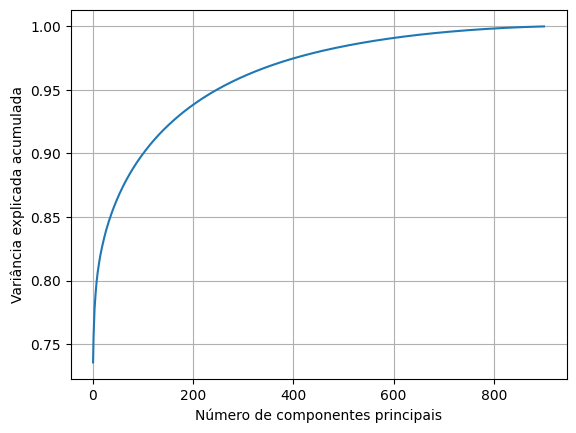

In [ ]:
plt.plot(np.arange(1, len(cum_var)+1), cum_var)
plt.xlabel("Número de componentes principais")
plt.ylabel("Variância explicada acumulada")
plt.grid(True)
plt.show()

Vemos que, com um número pequeno de componentes, já conseguimos acumular boa parte da variância explicada. Escolhi a grade de valores abaixo para testar na Regressão Logística com base nos resultados do gráfico e no print acima, que mostra o número de componentes necessário para atingir x% da variância. Dessa vez, vamos testar esses valores de n_components apenas na Regressão Logística, que escolhemos como modelo inicial. Embora o valor ideal de n_components possa variar de modelo para modelo, vou fixar um valor único para todos os classificadores, para termos uma comparação “justa” nesse espaço reduzido e deixar o experimento mais compacto (poupar tempo). Assim, a escolha será feita como um trade-off entre variância explicada e desempenho da Regressão Logística.

Fica como melhoria futura do projeto, com maior poder computacional, colocar a escolha do n_components do PCA dentro da pipeline de cada modelo.

In [ ]:
def testa_logreg_pca(n_components_list, X, y, cv=5):
    resultados = {}
    for n in n_components_list:
        print(f"\n===== PCA + RL com n_components = {n} =====")

        pipe = Pipeline([
            ("pca", PCA(n_components=n)),
            ("clf", LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                n_jobs=-1
            ))
        ])

        cm, y_pred = avalia_modelo(pipe, X, y, cv=cv)
        resultados[n] = (cm, y_pred)

    return resultados

# usando o recorte 30x30
lista_n = [30, 50, 100, 250, 600]
resultados_pca_rl = testa_logreg_pca(lista_n, X_train_rec30, y_train, cv=5)



===== PCA + RL com n_components = 30 =====
Matriz de confusão (linhas = verdade, colunas = previsão):
[[5384  616]
 [ 162  838]]

                precision    recall  f1-score   support

sem vulcão (0)       0.97      0.90      0.93      6000
com vulcão (1)       0.58      0.84      0.68      1000

      accuracy                           0.89      7000
     macro avg       0.77      0.87      0.81      7000
  weighted avg       0.91      0.89      0.90      7000


===== PCA + RL com n_components = 50 =====
Matriz de confusão (linhas = verdade, colunas = previsão):
[[5376  624]
 [ 158  842]]

                precision    recall  f1-score   support

sem vulcão (0)       0.97      0.90      0.93      6000
com vulcão (1)       0.57      0.84      0.68      1000

      accuracy                           0.89      7000
     macro avg       0.77      0.87      0.81      7000
  weighted avg       0.91      0.89      0.90      7000


===== PCA + RL com n_components = 100 =====
Matriz de confu

Podemos notar que quase todos os valores da grade obtiveram desempenho semelhante, ao mesmo tempo que quando aumentamos o n_components ganhamos informação, também aumentamos o ruído, logo o resultado para mais componentes não é necessariamente melhor. Para n_components = 50 obtivemos um resultado um pouco melhor com o que definimos que era mais importante, uma recall alto com um número reduzido de falsos negativos.

Logo vamos utilizar esse número de componentes para treinar os outros modelos, a redução da dimensão é significativa (de 900 para 50) e isso deve facilitar o treinamento deles.

Parte 2) Treinamento e validação dos modelos de Classificação

Nessa parte estarei optando por grades menores de hiperparâmetros para cada modelo, para que não demore tanto nos modelos mais complexos.

2.1) Definição de variáveis e separação dos conjuntos de treino e teste

In [ ]:
# treino
X_train = feat.values.astype(np.float32)
y_train = resp["Volcano?"].values.astype(int)

# teste
X_test = feat_test.values.astype(np.float32)
y_test = resp_test["Volcano?"].values.astype(int)

# escala 0–1
X_train_scaled = X_train / 255.0
X_test_scaled  = X_test  / 255.0

In [ ]:
# recorte central 30x30
X_train_rec30 = crop_center(X_train_scaled, img_size=110, crop_size=30)
X_test_rec30  = crop_center(X_test_scaled,  img_size=110, crop_size=30)

X_train_rec30.shape, X_test_rec30.shape

((7000, 900), (2734, 900))

2.2) Funções para rodar o GridSearchCV e para avaliação dos modelos no conjunto de Teste

In [ ]:
def roda_gridsearch(modelo, param_grid, X_train, y_train, scoring="recall", cv=5):
    """
    Roda GridSearchCV com validação cruzada estratificada e retorna o melhor modelo.
    scoring="recall" porque queremos priorizar recall da classe positiva (vulcões).
    """
    skf = StratifiedKFold(n_splits=cv, shuffle=True, random_state=42)

    grid = GridSearchCV(
        estimator=modelo,
        param_grid=param_grid,
        cv=skf,
        scoring=scoring,
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    print("Melhores hiperparâmetros:", grid.best_params_)
    print("Melhor score médio em CV (", scoring, "):", grid.best_score_)

    best_model = grid.best_estimator_
    return best_model, grid

In [ ]:
def avalia_no_teste(modelo, X_test, y_test, nome_modelo=None):
    # Descobre nome automaticamente se não for passado
    if nome_modelo is None:
        if isinstance(modelo, Pipeline) and "clf" in modelo.named_steps:
            nome_modelo = type(modelo.named_steps["clf"]).__name__
        else:
            nome_modelo = type(modelo).__name__

    print(f"\n===== Avaliação no conjunto de teste: {nome_modelo} =====\n")

    y_pred = modelo.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)
    print("Matriz de confusão (linhas = verdade, colunas = previsão):")
    print(cm)
    print()
    print(classification_report(
        y_test,
        y_pred,
        target_names=["sem vulcão (0)", "com vulcão (1)"]
    ))

    return cm, y_pred


2.3) Regressão Logística

In [ ]:
pipe_log = Pipeline([
    ("pca", PCA(n_components=50)),
    ("clf", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        n_jobs=-1
    ))
])

param_grid_log = {
    "clf__C": [0.1, 1, 10]
}

best_log, grid_log = roda_gridsearch(
    modelo=pipe_log,
    param_grid=param_grid_log,
    X_train=X_train_rec30,
    y_train=y_train,
    scoring="recall",
    cv=5
)

cm_log_test, y_pred_log_test = avalia_no_teste(
    best_log,
    X_test_rec30,
    y_test,
    nome_modelo="LogReg + PCA(50)"
)


Melhores hiperparâmetros: {'clf__C': 10}
Melhor score médio em CV ( recall ): 0.8480000000000001

===== Avaliação no conjunto de teste: LogReg + PCA(50) =====

Matriz de confusão (linhas = verdade, colunas = previsão):
[[2066  234]
 [  66  368]]

                precision    recall  f1-score   support

sem vulcão (0)       0.97      0.90      0.93      2300
com vulcão (1)       0.61      0.85      0.71       434

      accuracy                           0.89      2734
     macro avg       0.79      0.87      0.82      2734
  weighted avg       0.91      0.89      0.90      2734



A regressão logística apresentou um resultado parecido no conjunto de teste com o que estávamos vendo na parte 1 do relatório, quando estavamos apenas fazendo uma validação cruzada estratificada no conjunto de treino, o que mostra uma estabilidade do modelo e uma boa generalização.

Ele encontrou 85% dos vulcões com um número considerável(mas não absurdo como estávamos vendo no GaussianNB) de 234 falsos positivos, o modelo é agressivo mas não sai do controle.

2.4) GaussianNB

In [ ]:
pipe_gnb = Pipeline([
    ("pca", PCA(n_components=50)),
    ("clf", GaussianNB())
])

pipe_gnb.fit(X_train_rec30, y_train)

cm_gnb_test, y_pred_gnb_test = avalia_no_teste(
    pipe_gnb,
    X_test_rec30,
    y_test,
    nome_modelo="GaussianNB + PCA(50)"
)



===== Avaliação no conjunto de teste: GaussianNB + PCA(50) =====

Matriz de confusão (linhas = verdade, colunas = previsão):
[[2155  145]
 [ 199  235]]

                precision    recall  f1-score   support

sem vulcão (0)       0.92      0.94      0.93      2300
com vulcão (1)       0.62      0.54      0.58       434

      accuracy                           0.87      2734
     macro avg       0.77      0.74      0.75      2734
  weighted avg       0.87      0.87      0.87      2734



O GaussianNB não teve novamente um resultado satisfatório, deixando de detectar muitos vulcões, como dissemos anteriormente o modelo tem um número reduzido de falsos positivos em relação a Regressão Logística em troca de ter um número alto de falsos negativos que é o que queremos evitar.

Acredito que a pressuposição de independência do modelo não faz muito sentido nesse contexto e por isso não tem como esperar um bom resultado.

2.5) LDA

In [ ]:
pipe_lda = Pipeline([
    ("pca", PCA(n_components=50)),
    ("clf", LinearDiscriminantAnalysis())
])

param_grid_lda = {
    "clf__solver": ["lsqr"],
    "clf__shrinkage": ["auto", 0.1, 0.5, 0.9]
}

best_lda, grid_lda = roda_gridsearch(
    modelo=pipe_lda,
    param_grid=param_grid_lda,
    X_train=X_train_rec30,
    y_train=y_train,
    scoring="recall",
    cv=5
)

cm_lda_test, y_pred_lda_test = avalia_no_teste(
    best_lda,
    X_test_rec30,
    y_test,
    nome_modelo="LDA + PCA(50)"
)

Melhores hiperparâmetros: {'clf__shrinkage': 0.1, 'clf__solver': 'lsqr'}
Melhor score médio em CV ( recall ): 0.5569999999999999

===== Avaliação no conjunto de teste: LDA + PCA(50) =====

Matriz de confusão (linhas = verdade, colunas = previsão):
[[2281   19]
 [ 199  235]]

                precision    recall  f1-score   support

sem vulcão (0)       0.92      0.99      0.95      2300
com vulcão (1)       0.93      0.54      0.68       434

      accuracy                           0.92      2734
     macro avg       0.92      0.77      0.82      2734
  weighted avg       0.92      0.92      0.91      2734



O LDA encontrou um número parecido de vulcões com o GaussianNB mas com bem menos falsos positivos, provavelmente por conta da sua fronteira linear ele deixa de detectar muitos vulcões aqueles que não temos muita certeza. Pensei em mudar o limiar de decisão para ficar mais de acordo com aquilo o que queremos que é ter menos falsos negativos.

Uma melhoria futura poderia ser colocar as prioris do modelo nos hiperparâmetros e passar uma grade de valores para essa regra de decisão.

In [ ]:
# Probabilidades da classe 1 (com vulcão)
proba_lda_test = best_lda.predict_proba(X_test_rec30)[:, 1]

# Limiar
t = 0.2
y_pred_lda_t02 = (proba_lda_test >= t).astype(int)

# Matriz de confusão e métricas
cm_lda_t02 = confusion_matrix(y_test, y_pred_lda_t02)
print("\n===== Avaliação no conjunto de teste: LDA + PCA(50) com t = 0.2 =====\n")
print("Matriz de confusão (linhas = verdade, colunas = previsão):")
print(cm_lda_t02)
print()
print(classification_report(
    y_test,
    y_pred_lda_t02,
    target_names=["sem vulcão (0)", "com vulcão (1)"]
))


===== Avaliação no conjunto de teste: LDA + PCA(50) com t = 0.2 =====

Matriz de confusão (linhas = verdade, colunas = previsão):
[[2197  103]
 [ 113  321]]

                precision    recall  f1-score   support

sem vulcão (0)       0.95      0.96      0.95      2300
com vulcão (1)       0.76      0.74      0.75       434

      accuracy                           0.92      2734
     macro avg       0.85      0.85      0.85      2734
  weighted avg       0.92      0.92      0.92      2734



Com a mudança do limiar de decisão para 0.2, o modelo ficou bem mais balanceado e de acordo com o que queriamos, encontrou um número maior de vulcões e trocou uma quantidade de falsos negativos por falsos positivos que consideramos mais razoavel. Ainda assim o resultado é inferior ao da regressão logística.

2.6) QDA

In [ ]:
pipe_qda = Pipeline([
    ("pca", PCA(n_components=50)),
    ("clf", QuadraticDiscriminantAnalysis())
])

param_grid_qda = {
    "clf__reg_param": [0.0, 0.001, 0.01, 0.1, 0.3]
}

best_qda, grid_qda = roda_gridsearch(
    modelo=pipe_qda,
    param_grid=param_grid_qda,
    X_train=X_train_rec30,
    y_train=y_train,
    scoring="recall",
    cv=5
)

cm_qda_test, y_pred_qda_test = avalia_no_teste(
    best_qda,
    X_test_rec30,
    y_test,
    nome_modelo="QDA + PCA(50)"
)


Melhores hiperparâmetros: {'clf__reg_param': 0.001}
Melhor score médio em CV ( recall ): 0.8110000000000002

===== Avaliação no conjunto de teste: QDA + PCA(50) =====

Matriz de confusão (linhas = verdade, colunas = previsão):
[[2271   29]
 [  80  354]]

                precision    recall  f1-score   support

sem vulcão (0)       0.97      0.99      0.98      2300
com vulcão (1)       0.92      0.82      0.87       434

      accuracy                           0.96      2734
     macro avg       0.95      0.90      0.92      2734
  weighted avg       0.96      0.96      0.96      2734



O QDA apresentou um resultado muito satisfatório com um número baixo de falsos negativos, e quase nada de falsos positivos. Por ser mais flexível que o LDA parece ter se ajustado melhor aos dados e por conta do PCA e a diminuição da dimensão parece que não tivemos problemas para estimar as matrizes de covariância.

Vamos diminuir também o limiar de decisão para ver se conseguimos melhorar ainda mais o modelo.

In [ ]:
# Probabilidade da classe 1 (com vulcão)
proba_qda_test = best_qda.predict_proba(X_test_rec30)[:, 1]

# Limiar
t = 0.1
y_pred_qda_t01 = (proba_qda_test >= t).astype(int)

# Matriz de confusão e métricas
cm_qda_t01 = confusion_matrix(y_test, y_pred_qda_t01)
print("\n===== Avaliação no conjunto de teste: QDA + PCA(50) com t = 0.1 =====\n")
print("Matriz de confusão (linhas = verdade, colunas = previsão):")
print(cm_qda_t01)
print()
print(classification_report(
    y_test,
    y_pred_qda_t01,
    target_names=["sem vulcão (0)", "com vulcão (1)"]
))


===== Avaliação no conjunto de teste: QDA + PCA(50) com t = 0.1 =====

Matriz de confusão (linhas = verdade, colunas = previsão):
[[2169  131]
 [  39  395]]

                precision    recall  f1-score   support

sem vulcão (0)       0.98      0.94      0.96      2300
com vulcão (1)       0.75      0.91      0.82       434

      accuracy                           0.94      2734
     macro avg       0.87      0.93      0.89      2734
  weighted avg       0.95      0.94      0.94      2734



Com o limiar de 0.1 conseguimos aumentar ainda mais o número de vulcões encontrados, diminuindo consideralvemente o número de falsos negativos, em troca de um número um pouco maior de falsos positivos o que está de acordo com o que queremos, os cientistas podem revisar esses 131 falsos vulcões, o número não cresceu tanto a ficar fora de controle.

Até então o QDA apresentou o resultado mais satisfatório entre os modelos generativos.

2.7) LinearSVC

In [ ]:
pipe_svm = Pipeline([
    ("pca", PCA(n_components=50)),
    ("clf", LinearSVC(
        class_weight="balanced",
        dual=False,          # n_samples > n_features
        max_iter=5000
    ))
])

param_grid_svm = {
    "clf__C": [0.1, 1, 10]
}

best_svm, grid_svm = roda_gridsearch(
    modelo=pipe_svm,
    param_grid=param_grid_svm,
    X_train=X_train_rec30,
    y_train=y_train,
    scoring="recall",
    cv=5
)

cm_svm_test, y_pred_svm_test = avalia_no_teste(
    best_svm,
    X_test_rec30,
    y_test,
    nome_modelo="LinearSVC + PCA(50)"
)

Melhores hiperparâmetros: {'clf__C': 1}
Melhor score médio em CV ( recall ): 0.837

===== Avaliação no conjunto de teste: LinearSVC + PCA(50) =====

Matriz de confusão (linhas = verdade, colunas = previsão):
[[2073  227]
 [  70  364]]

                precision    recall  f1-score   support

sem vulcão (0)       0.97      0.90      0.93      2300
com vulcão (1)       0.62      0.84      0.71       434

      accuracy                           0.89      2734
     macro avg       0.79      0.87      0.82      2734
  weighted avg       0.91      0.89      0.90      2734



O LinearSVC teve um resultado bem parecido com a regressão logística, o que faz sentido pois ambos dividem o espaço das features linearmente. O resultado é razoável mas ainda não é tão satisfatório como tivemos com o LDA.

2.8) KNN

In [ ]:
pipe_knn = Pipeline([
    ("pca", PCA(n_components=50)),
    ("clf", KNeighborsClassifier())
])

param_grid_knn = {
    "clf__n_neighbors": [3, 5, 7, 11],
    "clf__weights": ["uniform", "distance"]
}

best_knn, grid_knn = roda_gridsearch(
    modelo=pipe_knn,
    param_grid=param_grid_knn,
    X_train=X_train_rec30,
    y_train=y_train,
    scoring="recall",
    cv=5
)

cm_knn_test, y_pred_knn_test = avalia_no_teste(
    best_knn,
    X_test_rec30,
    y_test,
    nome_modelo="KNN + PCA(50)"
)

Melhores hiperparâmetros: {'clf__n_neighbors': 3, 'clf__weights': 'distance'}
Melhor score médio em CV ( recall ): 0.6910000000000001

===== Avaliação no conjunto de teste: KNN + PCA(50) =====

Matriz de confusão (linhas = verdade, colunas = previsão):
[[2270   30]
 [ 137  297]]

                precision    recall  f1-score   support

sem vulcão (0)       0.94      0.99      0.96      2300
com vulcão (1)       0.91      0.68      0.78       434

      accuracy                           0.94      2734
     macro avg       0.93      0.84      0.87      2734
  weighted avg       0.94      0.94      0.94      2734



O KNN apresentou um resultado esperado em relação as pressuposições do modelo, apenas no espaço em que os vizinhos são dominadas por vulcões que o modelo classifica dessa forma, o que faz com que tenhamos poucos falsos positivos e um número alto de falsos negativos que não é exatamente o que queremos.

2.9) Random Forest

2.9.1) Random Forest com PCA(não é necessário mas farei para ficar "justo" em comparação com os outros modelos

In [ ]:
from sklearn.ensemble import RandomForestClassifier

pipe_rf = Pipeline([
    ("pca", PCA(n_components=50)),
    ("clf", RandomForestClassifier(
        random_state=42,
        n_jobs=-1,
    ))
])

param_grid_rf = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [None, 10, 20],
    "clf__max_features": ["sqrt", "log2"]
}

best_rf, grid_rf = roda_gridsearch(
    modelo=pipe_rf,
    param_grid=param_grid_rf,
    X_train=X_train_rec30,
    y_train=y_train,
    scoring="recall",
    cv=5
)

cm_rf_test, y_pred_rf_test = avalia_no_teste(
    best_rf,
    X_test_rec30,
    y_test,
    nome_modelo="RandomForest + PCA(50)"
)


Melhores hiperparâmetros: {'clf__max_depth': 20, 'clf__max_features': 'sqrt', 'clf__n_estimators': 200}
Melhor score médio em CV ( recall ): 0.6839999999999999

===== Avaliação no conjunto de teste: RandomForest + PCA(50) =====

Matriz de confusão (linhas = verdade, colunas = previsão):
[[2294    6]
 [ 139  295]]

                precision    recall  f1-score   support

sem vulcão (0)       0.94      1.00      0.97      2300
com vulcão (1)       0.98      0.68      0.80       434

      accuracy                           0.95      2734
     macro avg       0.96      0.84      0.89      2734
  weighted avg       0.95      0.95      0.94      2734



2.9.2) Random Forest sem PCA

In [ ]:
# Modelo RF sem PCA (usando diretamente o recorte 30x30: 900 features)
rf_no_pca = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Grade de hiperparâmetros para o RF sem PCA
param_grid_rf_no_pca = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "max_features": ["sqrt", "log2"]
}

# GridSearchCV só no conjunto de treino
best_rf_no_pca, grid_rf_no_pca = roda_gridsearch(
    modelo=rf_no_pca,
    param_grid=param_grid_rf_no_pca,
    X_train=X_train_rec30,  # recorte 30x30 sem PCA
    y_train=y_train,
    scoring="recall",       # priorizando recall da classe com vulcão
    cv=5
)

# Avaliação no conjunto de teste
cm_rf_no_pca_test, y_pred_rf_no_pca_test = avalia_no_teste(
    best_rf_no_pca,
    X_test_rec30,
    y_test,
    nome_modelo="RandomForest (sem PCA, recorte 30x30)"
)


Melhores hiperparâmetros: {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 100}
Melhor score médio em CV ( recall ): 0.585

===== Avaliação no conjunto de teste: RandomForest (sem PCA, recorte 30x30) =====

Matriz de confusão (linhas = verdade, colunas = previsão):
[[2285   15]
 [ 172  262]]

                precision    recall  f1-score   support

sem vulcão (0)       0.93      0.99      0.96      2300
com vulcão (1)       0.95      0.60      0.74       434

      accuracy                           0.93      2734
     macro avg       0.94      0.80      0.85      2734
  weighted avg       0.93      0.93      0.93      2734



O Random Forest apresentou um bom resultado de forma a diminuir bastante os erros de falsos positivos. O resultado do Random Forest com PCA foi melhor do que sem, vou tentar ajustar o limiar de decisão para ficar mais de acordo com o que queremos, um número baixo de falsos negativos em troca de mais falsos positivos.

In [ ]:
# Probabilidade da classe 1 (com vulcão)
proba_rf_test = best_rf.predict_proba(X_test_rec30)[:, 1]

# Escolha do limiar
t = 0.2
y_pred_rf_t03 = (proba_rf_test >= t).astype(int)

# Matriz de confusão e métricas
cm_rf_t03 = confusion_matrix(y_test, y_pred_rf_t03)
print("\n===== Avaliação no conjunto de teste: RandomForest + PCA(50) com t = 0.2 =====\n")
print("Matriz de confusão (linhas = verdade, colunas = previsão):")
print(cm_rf_t03)
print()
print(classification_report(
    y_test,
    y_pred_rf_t03,
    target_names=["sem vulcão (0)", "com vulcão (1)"]
))


===== Avaliação no conjunto de teste: RandomForest + PCA(50) com t = 0.2 =====

Matriz de confusão (linhas = verdade, colunas = previsão):
[[2108  192]
 [  22  412]]

                precision    recall  f1-score   support

sem vulcão (0)       0.99      0.92      0.95      2300
com vulcão (1)       0.68      0.95      0.79       434

      accuracy                           0.92      2734
     macro avg       0.84      0.93      0.87      2734
  weighted avg       0.94      0.92      0.93      2734



Com um limiar de 0.2, conseguimos o resultado satisfátorio, um número baixissimo de falsos negativos em troca de um número maior de falsos positivos que os cientistas podem checar. O Random Forest apresentou o melhor resultado geral entre todos os modelos.

3)Conclusões

Resultados:

O QDA e o Random Forest foram os grandes "vencedores" entre todos os modelos, o Random Forest teve o melhor resultado geral com o limiar ajustado, se apenas estivermos nos preocupando em minimizar o número de falsos negativos e maximizar o número de vulcões encontrados, sem deixar o número de falsos positivos explodir. Agora, se considerarmos o custo computacional, o QDA é a melhor escolha, pois teve um resultado muito bom, com um ajuste bem rápido.

A Regressão Logística também deve ser pontuada, já que serviu como base para toda nossa construção e teve um ótimo resultado também, considerando que é um modelo relativamente mais simples.

Melhorias futuras:

-Fazer o PCA otimizado para cada modelo individualmente.

-Aumentar a grade de hiperparâmetros para cada modelo, o que deve melhorar ainda mais o resultado dos modelos mais flexíveis.

-Incluir o limiar de decisão dos modelos como hiperparâmetros em uma grade específica, para que tenha ainda menos falsos negativos sem deixar o número de falsos positivos explodir, já que os limiares foram escolhidos de forma exploratória.
